# 01. 문제 정의 — 가입자는 3배, QAU는 정체

**요약** (아래 섹션의 숫자를 모은 것)

- **현상**: 2020 → 2025년 분기 신규 가입자는 **연 +27.9%** (90% CI 26.4 ~ 29.4%) 늘었지만, QAU는 **연 +0.5%** (−0.9 ~ +1.9%)다. 황금기 → 침체기 분기 평균은 가입자 ×2.91, QAU ×1.00.
- **정체 판정**: QAU 증가율의 90% CI가 ±5%(엄격하게 ±2%) 안 → 동등성 검정(TOST) 기준 **정체**. 가입자 탄력성 0.026 (가입자 10% 증가 → QAU 0.26% 증가).
- **구성**: 정체는 상쇄의 결과다. 창작자 연 +8.3%, 팀 합류만(대회 참가만) 연 −3.5%.
- **견고성**: 월 단위(MAU) +0.6% (−0.6 ~ +1.7%), 2025-Q4 제외 −0.2%, HAC 시차 변경에도 같은 판정.
- **신규 유입의 활성화**: 가입 후 90일 안에 참여·창작을 시작한 비율이 2019년 16.7% → 황금기 12.7% → 침체기 **3.6%**. 2017년부터 점진적으로 하락.
- **가설**: H1 유입 질(활성화율), H2 활성화 병목(참여 → D 전환율). 판정 기준은 상대 차이 5%·10%로 검증 전에 고정.

| 섹션 | 질문 |
|---|---|
| §1 | 이 데이터로 무엇을 측정할 수 있나 (정의와 한계) |
| §2 | 가입자와 QAU는 실제로 어떻게 움직였나 |
| §3 | "정체"를 통계적으로 말할 수 있나 (동등성 검정) |
| §4 | 분기 단위가 맞나 (재활동 간격, MAU 견고성) |
| §5 | 비교할 코호트를 어떻게 골랐나 |
| §6 | 검증할 가설과 판정 기준 |

입력: `data/processed/` (`scripts/01_activity_series.py`)

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.regression.linear_model import OLS

sys.path.append("../src")
sys.path.append(os.path.expanduser("~/.claude/skills/chart-style"))
from metakaggle.config import processed
import viz_style as vs

vs.setup()
FIG = "../docs/figures"
q = pd.read_parquet(processed("quarterly_series")).set_index("q")
# 팀 합류 기록이 2017-Q1에 직전 분기의 2.6배로 뛴다 (같은 시기 제출 수는 오히려 감소) → 기록 방식 변화로 보고 2017년부터 사용
q = q.loc["2017-Q1":]
m = pd.read_parquet(processed("monthly_series")).set_index("ym")
gaps = pd.read_parquet(processed("qau_activity_gaps"))
q["activation_rate"] = q.activated_90d / q.new_users

GOLDEN_Q = ["2020-Q1", "2020-Q2", "2020-Q3", "2020-Q4"]
STAG_Q = ["2024-Q3", "2024-Q4", "2025-Q1", "2025-Q2"]
q.tail(4)

,new_users,activated_90d,qau,qau_creators,qau_team_only,activation_rate
q,,,,,,
2025-Q1,1565603,53547.0,184110,80091.0,104019.0,0.034202
2025-Q2,1596419,53634.0,204902,94503.0,110399.0,0.033596
2025-Q3,1571906,51819.0,186046,78639.0,107407.0,0.032966
2025-Q4,2257855,84526.0,244222,101602.0,142620.0,0.037436


## §1 데이터와 측정 한계

**Meta Kaggle에는 흔적을 남기는 행동만 기록된다.** 투표, 글, 노트북, 제출은 있지만 방문·조회·다운로드·로그인은 없다. 그래서 이 프로젝트의 "활성"은 **참여·창작 활동**으로 정의한다.

| 용어 | 정의 |
|---|---|
| **QAU** | 분기에 아래 활동을 1회 이상 한 전체 유저 (가입 시점 무관) |
| └ 참여 | 팀 합류 (대회에 참가하면 1인 팀이 생김) |
| └ 창작 | 노트북 버전 작성·공개, 대회 제출, 포럼 글, 데이터셋·모델 버전, 데이터셋 태스크 |
| 제외 | 투표, 팔로우, 반응 (가벼운 반응은 참여 의지의 신호로 약함) |
| **D 활동** (핵심 창작) | 노트북 공개, 대회 제출(팀 단위), 포럼 글, 데이터셋 버전·태스크, 모델 버전. QAU ⊃ D |
| **90일 활성화율** | 가입 코호트 중 가입 후 90일 안에 QAU 활동을 시작한 비율 |

**날짜 정밀도:** 가입일·팀 합류·제출·투표는 날짜만, 노트북 버전·포럼 글·데이터셋 버전은 시각까지 기록된다. 가입 시각이 없으므로 "가입 후 n시간" 지표는 만들지 않고 일 단위로만 비교한다.

**기록 범위:** 팀 합류 기록이 2017-Q1에 직전 분기의 2.6배(3.2만 → 8.3만 건)로 뛰는데 같은 시기 대회 제출 수는 오히려 줄었다. 실제 행동 변화보다 기록 방식 변화로 보고 **2017-Q1부터** 쓴다. 추세 검정은 2020년 이후라 영향이 없다.

## §2 현상: 가입자는 늘고 QAU는 제자리

QAU를 **창작자**(창작 활동이 1번이라도 있는 유저)와 **팀 합류만** 한 유저로 나눠 쌓았다. 두 막대의 합이 QAU다.

[]


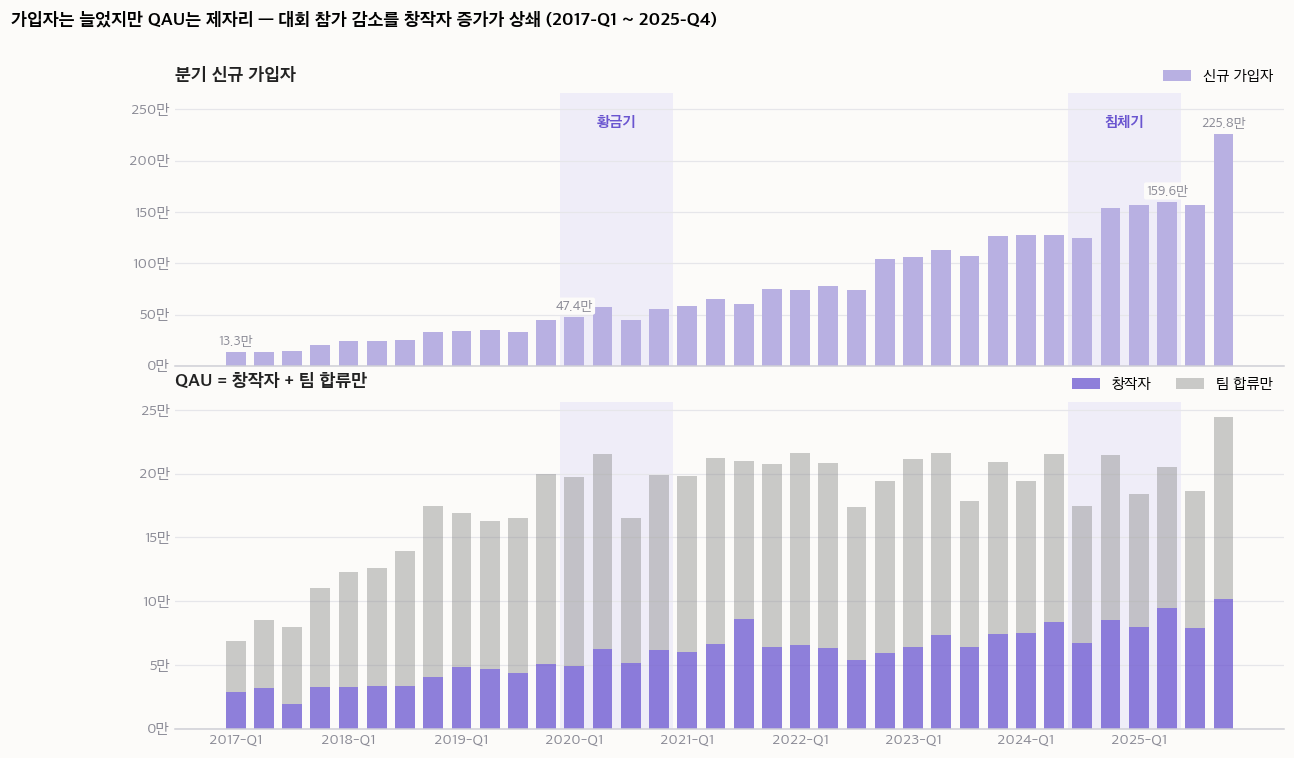

In [2]:
x = np.arange(len(q)); lab = q.index.tolist()
g0, g1, s0, s1 = lab.index("2020-Q1"), lab.index("2020-Q4"), lab.index("2024-Q3"), lab.index("2025-Q2")
fig, (a1, a2) = vs.stacked_panels(height_ratios=(1, 1.2), figsize=(13, 7.5))
for ax in (a1, a2):
    vs.shade(ax, g0, g1, label="황금기" if ax is a1 else None)
    vs.shade(ax, s0, s1, label="침체기" if ax is a1 else None)
a1.bar(x, q.new_users, color=vs.LAVENDER, width=0.7, label="신규 가입자")
vs.label_bars(a1, [b for i, b in enumerate(a1.patches[-len(x):]) if i in (0, g0, s1, len(x) - 1)], fmt=vs.fmt_man)
vs.yfmt(a1, lambda v: f"{v/1e4:.0f}만"); vs.panel_title(a1, "분기 신규 가입자")
b1 = a2.bar(x, q.qau_creators, color=vs.PURPLE, alpha=0.75, width=0.7, label="창작자")
a2.bar(x, q.qau_team_only, bottom=q.qau_creators, color=vs.GRAY, alpha=0.45, width=0.7, label="팀 합류만")
vs.yfmt(a2, lambda v: f"{v/1e4:.0f}만"); vs.panel_title(a2, "QAU = 창작자 + 팀 합류만")
a2.set_xticks(x[::4]); a2.set_xticklabels(lab[::4])
vs.legend_top_right(a1); vs.legend_top_right(a2)
fig.suptitle("가입자는 늘었지만 QAU는 제자리 — 대회 참가 감소를 창작자 증가가 상쇄 (2017-Q1 ~ 2025-Q4)", x=0.01, ha="left", fontweight="bold")
fig.savefig(f"{FIG}/01_signups_vs_qau.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

In [3]:
def period_mean(df, idx): return df.loc[idx].mean()
cols = ["new_users", "qau", "qau_creators", "qau_team_only"]
comp = pd.DataFrame({"2019": period_mean(q[cols], [f"2019-Q{i}" for i in range(1, 5)]),
                     "황금기 2020": period_mean(q[cols], GOLDEN_Q),
                     "침체기 2024-Q3~2025-Q2": period_mean(q[cols], STAG_Q)})
comp["배수 (침체/황금)"] = (comp.iloc[:, 2] / comp.iloc[:, 1]).round(2)
comp.index = ["신규 가입자 (분기 평균)", "QAU", "└ 창작자", "└ 팀 합류만"]
comp.style.format({c: "{:,.0f}" for c in comp.columns[:3]} | {"배수 (침체/황금)": "{:.2f}"})

,2019,황금기 2020,침체기 2024-Q3~2025-Q2,배수 (침체/황금)
신규 가입자 (분기 평균),"365,432","510,498","1,485,893",2.91
QAU,"174,096","194,125","194,678",1.00
└ 창작자,"47,296","56,200","81,720",1.45
└ 팀 합류만,"126,800","137,924","112,958",0.82


**가입자 대비 활성 비율(QAU / 당분기 가입자)은 쓰지 않는다.** 분자는 전체 유저, 분모는 그 분기 신규 가입자라 같은 집단의 비율이 아니다. 가입자가 늘면 행동이 그대로여도 숫자가 기계적으로 떨어진다. 같은 집단 안에서 계산하는 **90일 활성화율**(§5)을 쓴다.

## §3 "정체"의 통계적 판정

### 3.1 왜 동등성 검정인가
"추세가 유의하지 않다"는 **변화를 못 찾았다**는 뜻이지 **변화가 없다**는 증거가 아니다 (분기 24개면 검정력이 낮다). 그래서 가설을 뒤집는다.

- H0: 연간 변화율이 ±δ 밖에 있다 (정체가 아니다)
- H1: 연간 변화율이 ±δ 안에 있다 (정체다)
- 판정: 연간 변화율의 **90% CI가 [−δ, +δ] 안에 완전히 들어가면** 정체 (한쪽 검정 두 번을 각 5%로 하는 TOST와 같은 판정)
- **δ = 5%**: 같은 기간 가입자 성장률(연 약 28%)의 1/5 미만이면 "가입자 증가를 따라가지 못한 정체"로 본다. 결론이 δ에 기대지 않는지 δ = 2%도 함께 본다.

### 3.2 성장 모형: 직선형 vs 지수형
`y ~ t`는 "매년 같은 인원", `log(y) ~ t`는 "매년 같은 비율"을 가정한다. 신규 가입자로 어느 쪽이 맞는지 확인한다.

In [4]:
def design(index, freq):
    n = len(index)
    X = pd.DataFrame({"const": 1.0, "t": np.arange(n) / (4 if freq == "Q" else 12)}, index=index)
    season = index.str[-2:]
    for s in sorted(set(season))[1:]:          # 첫 분기(월)를 기준으로 나머지만 더미
        X[f"s_{s}"] = (season == s).astype(float)
    return X

def fit_compare(y, freq="Q"):
    X = design(y.index, freq)
    lin = OLS(y.astype(float), X).fit(); lg = OLS(np.log(y.astype(float)), X).fit()
    p_lin, p_log = lin.fittedvalues, np.exp(lg.fittedvalues)
    thirds = lambda r: " → ".join(f"{v:+.1f}%" for v in [r[:len(r)//3].mean(), r[len(r)//3:2*len(r)//3].mean(), r[2*len(r)//3:].mean()])
    return pd.Series({"MAPE 직선형": f"{(abs(y - p_lin) / y).mean():.1%}", "MAPE 지수형": f"{(abs(y - p_log) / y).mean():.1%}",
                      "잔차 3등분 직선형": thirds(((y - p_lin) / y * 100).values), "잔차 3등분 지수형": thirds(((y - p_log) / y * 100).values)})

TREND = slice("2020-Q1", "2025-Q4")
fit_compare(q.loc[TREND, "new_users"]).to_frame("신규 가입자 2020-Q1 ~ 2025-Q4")

,신규 가입자 2020-Q1 ~ 2025-Q4
MAPE 직선형,8.9%
MAPE 지수형,4.5%
잔차 3등분 직선형,+7.9% → -6.2% → -0.2%
잔차 3등분 지수형,-0.7% → +1.9% → -1.7%


지수형이 오차가 작고 잔차에 패턴이 없다 → `log(y) ~ t`로 성장 속도를 요약한다.

### 3.3 회귀식과 결과

$$\log(Y_q) = \beta_0 + \beta_1 t_q + \gamma_2 Q2_q + \gamma_3 Q3_q + \gamma_4 Q4_q + \varepsilon_q$$

- `t` = 2020-Q1부터 지난 연수 (0, 0.25, …), Q2 ~ Q4 = 분기 더미 (Q1 기준) → 계절성 제거
- 연간 증가율 = $e^{\beta_1} - 1$ (1년 뒤 $Y$가 $e^{\beta_1}$배)
- 표준오차: HAC (Newey-West). 이웃 분기끼리 비슷하게 움직이는 자기상관을 보정
- 지표마다 회귀를 따로 돌린다 (Y만 바꿈)

In [5]:
def annual_growth(y, freq="Q", maxlags=None, alpha=0.10):
    X = design(y.index, freq)
    r = OLS(np.log(y.astype(float)), X).fit(cov_type="HAC", cov_kwds={"maxlags": maxlags or (2 if freq == "Q" else 6)})
    lo, hi = r.conf_int(alpha=alpha).loc["t"]
    return np.expm1(r.params["t"]), np.expm1(lo), np.expm1(hi)

def tost_table(df, cols, names, freq="Q", **kw):
    rows = []
    for c, n in zip(cols, names):
        g, lo, hi = annual_growth(df[c], freq, **kw)
        rows.append({"지표": n, "연간 증가율": g, "90% CI 하한": lo, "90% CI 상한": hi,
                     "정체 (δ=5%)": (lo > -0.05) and (hi < 0.05), "정체 (δ=2%)": (lo > -0.02) and (hi < 0.02)})
    return pd.DataFrame(rows).set_index("지표")

pct = lambda v: f"{v:+.1%}"
cols, names = ["new_users", "qau", "qau_creators", "qau_team_only"], ["신규 가입자", "QAU", "└ 창작자", "└ 팀 합류만"]
tq = tost_table(q.loc[TREND], cols, names)
tq.style.format({c: pct for c in ["연간 증가율", "90% CI 하한", "90% CI 상한"]})

,연간 증가율,90% CI 하한,90% CI 상한,정체 (δ=5%),정체 (δ=2%)
지표,,,,,
신규 가입자,+27.9%,+26.4%,+29.4%,False,False
QAU,+0.5%,-0.9%,+1.9%,True,True
└ 창작자,+8.3%,+6.3%,+10.3%,False,False
└ 팀 합류만,-3.5%,-5.4%,-1.7%,False,False


In [6]:
# 탄력성: log(QAU) = a + η·log(가입자) + 분기 더미 → 가입자 1% 증가 시 QAU 몇 % 증가
X = design(q.loc[TREND].index, "Q").drop(columns="t"); X["log_new"] = np.log(q.loc[TREND, "new_users"].astype(float))
r = OLS(np.log(q.loc[TREND, "qau"].astype(float)), X).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
lo, hi = r.conf_int(alpha=0.10).loc["log_new"]
print(f"탄력성 η = {r.params['log_new']:.3f}  (90% CI {lo:.3f} ~ {hi:.3f})")

# 견고성: 가입자가 급증한 마지막 분기 제외, HAC 시차 변경
sens = pd.DataFrame({
    "기본 (2020-Q1~2025-Q4, 시차 2)": annual_growth(q.loc[TREND, "qau"]),
    "2025-Q4 제외": annual_growth(q.loc["2020-Q1":"2025-Q3", "qau"]),
    "HAC 시차 4": annual_growth(q.loc[TREND, "qau"], maxlags=4),
}, index=["연간 증가율", "90% CI 하한", "90% CI 상한"]).T
sens.style.format(pct)

탄력성 η = 0.026  (90% CI -0.031 ~ 0.083)


,연간 증가율,90% CI 하한,90% CI 상한
"기본 (2020-Q1~2025-Q4, 시차 2)",+0.5%,-0.9%,+1.9%
2025-Q4 제외,-0.2%,-1.3%,+1.0%
HAC 시차 4,+0.5%,-0.7%,+1.6%


## §4 집계 단위: 분기가 맞나

### 4.1 재활동 간격
활동 판정 기간은 유저가 보통 돌아오는 간격을 덮을 만큼 길어야 한다 (짧으면 쉬는 중인 유저가 비활성으로, 길면 떠난 유저가 활성으로 잡힌다). 2023 ~ 2024년 QAU 활동일마다 다음 활동까지 간격을 쟀다 (데이터 끝까지 15개월 이상 추적).

In [7]:
bins = [0, 7, 30, 90, 180, 365, np.inf]; labels = ["1~7일", "8~30일", "31~90일", "91~180일", "181~365일", "365일 초과·복귀 없음"]
g = gaps.assign(gap=gaps.gap.fillna(np.inf))
by_day = pd.cut(g.gap, bins=bins, labels=labels, right=True).value_counts(normalize=True).sort_index()
per_user = gaps.groupby("UserId").agg(n=("d", "size"), med=("gap", "median"))   # 마지막 활동일(다음 활동 없음)은 중앙값에서 제외
repeat = per_user[per_user.n >= 2]
by_user = pd.cut(repeat.med, bins=bins, labels=labels).value_counts(normalize=True).sort_index()
returned = g[np.isfinite(g.gap)]
print(f"활동일 {len(g):,}건, 유저 {len(per_user):,}명, 기간 내 하루만 활동한 유저 {(per_user.n == 1).mean():.1%}")
print(f"복귀한 경우 중 30일 이내 {(returned.gap <= 30).mean():.1%}, 90일 이내 {(returned.gap <= 90).mean():.1%}")
pd.DataFrame({"활동일 기준": by_day, f"반복 유저의 간격 중앙값 (n={len(repeat):,})": by_user}).style.format("{:.1%}")

활동일 4,373,927건, 유저 1,134,225명, 기간 내 하루만 활동한 유저 60.3%
복귀한 경우 중 30일 이내 81.7%, 90일 이내 89.4%


,활동일 기준,"반복 유저의 간격 중앙값 (n=450,209)"
1~7일,53.3%,44.0%
8~30일,10.2%,19.5%
31~90일,6.0%,15.0%
91~180일,3.3%,9.8%
181~365일,2.9%,8.6%
365일 초과·복귀 없음,24.3%,3.2%


### 4.2 MAU로도 정체인가
재활동 간격만으로는 분기와 월 중 하나를 고르기 어렵다 (복귀의 대부분은 30일 안, 반복 유저 셋 중 하나는 평소 간격이 30일 초과). 그래서 **월 단위(MAU)로 같은 검정을 반복**한다. 결론이 같으면 단위 선택이 결론을 만든 게 아니다.

In [8]:
tm = tost_table(m, ["new_users", "mau", "mau_creators", "mau_team_only"], ["신규 가입자", "MAU", "└ 창작자", "└ 팀 합류만"], freq="M")
tm.style.format({c: pct for c in ["연간 증가율", "90% CI 하한", "90% CI 상한"]})

,연간 증가율,90% CI 하한,90% CI 상한,정체 (δ=5%),정체 (δ=2%)
지표,,,,,
신규 가입자,+27.7%,+26.3%,+29.2%,False,False
MAU,+0.6%,-0.6%,+1.7%,True,True
└ 창작자,+8.7%,+7.2%,+10.3%,False,False
└ 팀 합류만,-4.2%,-6.0%,-2.4%,False,False


[]


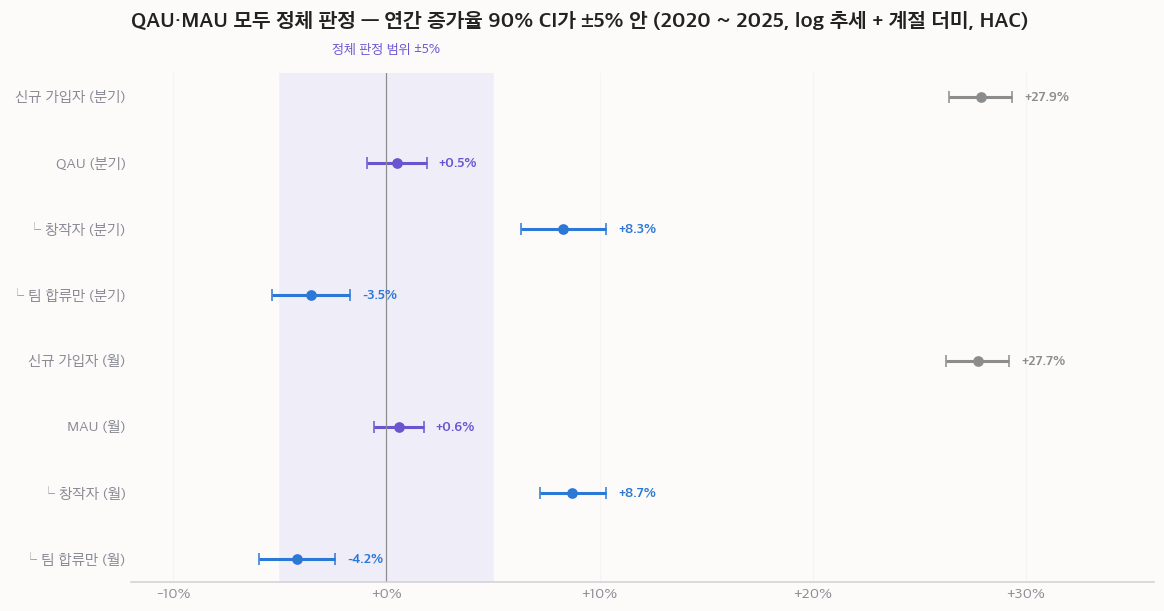

In [9]:
# 동등성 검정 결과 그림: 연간 증가율과 90% CI, 정체 판정 범위(±5%) 음영
rows = pd.concat([tq.assign(단위="분기"), tm.assign(단위="월")])
rows = rows.iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 6))
ax.axvspan(-0.05, 0.05, color=vs.SHADE, zorder=0)
ax.text(0, len(rows) - 0.35, "정체 판정 범위 ±5%", ha="center", color=vs.PURPLE, fontsize=9)
ypos = np.arange(len(rows))
for y, (name, r) in zip(ypos, rows.iterrows()):
    color = vs.GRAY if "가입자" in name else (vs.PURPLE if name in ("QAU", "MAU") else vs.BLUE)
    ax.errorbar(r["연간 증가율"], y, xerr=[[r["연간 증가율"] - r["90% CI 하한"]], [r["90% CI 상한"] - r["연간 증가율"]]],
                fmt="o", color=color, capsize=4, ms=6, lw=2)
    ax.annotate(f"{r['연간 증가율']:+.1%}", (r["90% CI 상한"], y), xytext=(8, 0), textcoords="offset points",
                va="center", color=color, fontsize=9, fontweight="bold")
ax.set_yticks(ypos); ax.set_yticklabels([f"{n} ({u})" for n, u in zip(rows.index, rows["단위"])])
ax.axvline(0, color=vs.GRAY, lw=0.8)
vs.yfmt(ax, lambda v: v) if False else None
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.grid(axis="y", visible=False); ax.grid(axis="x", alpha=0.3)
ax.set_xlim(-0.12, 0.36)
ax.set_title("QAU·MAU 모두 정체 판정 — 연간 증가율 90% CI가 ±5% 안 (2020 ~ 2025, log 추세 + 계절 더미, HAC)", loc="left", fontweight="bold")
fig.savefig(f"{FIG}/01_tost_growth.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

## §5 코호트 선정

비교 시기는 **같은 길이(4분기), 같은 계절 구성, 모든 가입자가 90일 관찰을 마친** 두 구간이다.
- 황금기 2020-Q1 ~ Q4 / 침체기 2024-Q3 ~ 2025-Q2
- 활성화율은 한 번에 꺾인 게 아니라 점진적으로 내려왔다 → 두 구간은 "단절 전후"가 아니라 **추세의 양 끝 대조**다.

[]


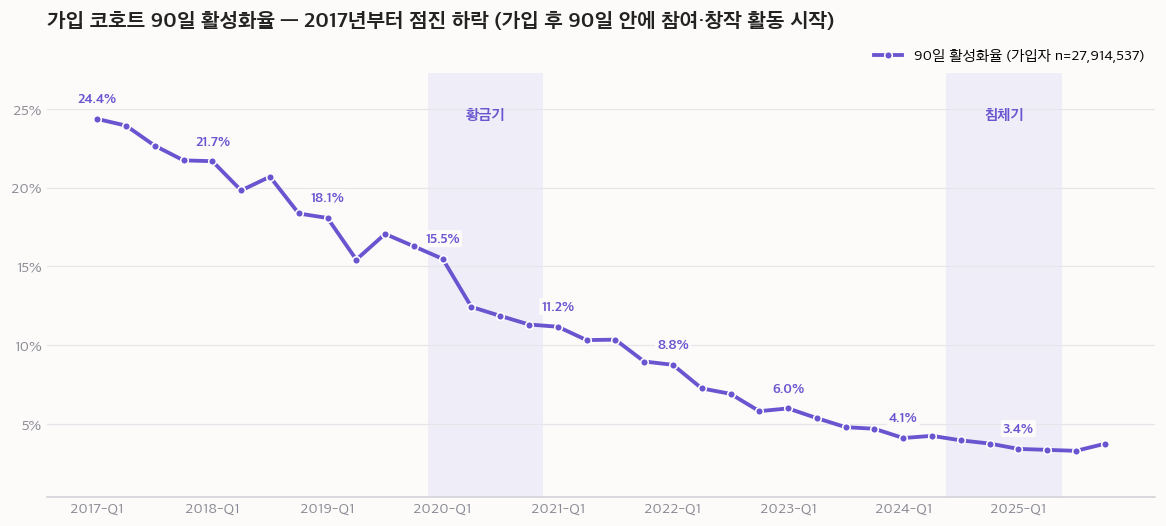

In [10]:
fig, ax = plt.subplots(figsize=(13, 5))
vs.shade(ax, g0, g1, label="황금기"); vs.shade(ax, s0, s1, label="침체기")
vs.line(ax, x, q.activation_rate.values, vs.PURPLE, vs.n_label("90일 활성화율", int(q.new_users.sum())).replace("n=", "가입자 n="))
vs.label_lines(ax, x, [(q.activation_rate.values, vs.PURPLE)], fmt=lambda v: f"{v:.1%}", every=4)
vs.yfmt(ax, lambda v: f"{v:.0%}")
ax.set_xticks(x[::4]); ax.set_xticklabels(lab[::4])
ax.set_title("가입 코호트 90일 활성화율 — 2017년부터 점진 하락 (가입 후 90일 안에 참여·창작 활동 시작)", loc="left", fontweight="bold")
vs.legend_top_right(ax)
fig.savefig(f"{FIG}/01_activation_rate.png", dpi=120, bbox_inches="tight")
print(vs.check_overlaps(fig))

In [11]:
act = pd.DataFrame({
    "2019": q.loc[[f"2019-Q{i}" for i in range(1, 5)], ["new_users", "activated_90d"]].sum(),
    "황금기 2020": q.loc[GOLDEN_Q, ["new_users", "activated_90d"]].sum(),
    "침체기": q.loc[STAG_Q, ["new_users", "activated_90d"]].sum(),
    "2025-Q3~Q4": q.loc[["2025-Q3", "2025-Q4"], ["new_users", "activated_90d"]].sum()}).T
act["90일 활성화율"] = act.activated_90d / act.new_users
act.style.format({"new_users": "{:,.0f}", "activated_90d": "{:,.0f}", "90일 활성화율": "{:.2%}"})

,new_users,activated_90d,90일 활성화율
2019,"1,461,730","243,589",16.66%
황금기 2020,"2,041,992","259,568",12.71%
침체기,"5,943,573","214,286",3.61%
2025-Q3~Q4,"3,829,761","136,345",3.56%


- **2020년(코로나)은 예외 연도가 아니다**: 2020년 활성화율이 2019년보다 높지 않다. 코로나는 가입자 수만 키웠다.
- 침체기 뒤 두 분기(2025-Q3 ~ Q4)도 같은 수준으로 추세가 이어진다. 2025-Q4는 가입자가 급증한 분기(원인 미확인)라 추세 판정의 견고성 확인에서 빼 봤다 (§3.3).

## §6 가설과 판정 기준 (검증 전에 고정)

n이 수백만이라 두 시기 차이는 항상 p ≈ 0이다. 그래서 **실무적으로 의미 있는 크기인가**로 판정하고, 기준을 두 개(5%, 10%)로 둬서 민감도를 본다.

| | H1 유입 질 (Acquisition) | H2 활성화 병목 (Activation) |
|---|---|---|
| 가설 | 침체기 가입자는 황금기보다 90일 안에 참여를 덜 시작한다 | 참여를 시작한 유저가 핵심 창작(D)까지 덜 간다 |
| 대상 | 두 시기 신규 가입자 전체 | 90일 안에 **비-D 참여**(팀 합류, 노트북 작성)로 시작한 유저 |
| 주 지표 | 90일 활성화율 | 90일 내 D 전환율 |
| 보조 지표 | 가입 당일 활동률, 첫 활동 유형, 대회 참가율 | 첫 참여 → D까지 일수 |
| 지지 | 침체기가 상대적으로 기준(5%·10%) 이상 낮고, 차이의 95% CI도 기준 밖 | 같음 |
| 기각 | 차이가 기준 안 (동등) 또는 침체기가 높음 | 같음 |
| 견고성 | 활동 정의에 가벼운 활동(투표 등) 포함 | 시도자(C그룹) 정의: 팀 합류 OR 노트북 최종 50줄↑ OR 수정 4회↑, 문턱 30·100줄 / 2·8회 |
| 해석 주의 | — | 조건부 비교라 선택 편향: 침체기 참여자는 더 걸러진 집단 |
| 지지 시 액션 | 유입 채널·타깃팅 점검 | 온보딩·대회 난이도 개선 |

## 결론

1. **문제는 "QAU 감소"가 아니라 "가입자 증가가 QAU로 이어지지 않음"이다.** QAU는 연 ±2% 안에서 움직이는 동안 가입자는 연 28% 늘었다.
2. **정체 안에서 구성이 바뀌고 있다.** 대회 참가만 하는 유저는 줄고(연 −3.5%), 창작자는 늘었다(연 +8.3%). 대회 참가 감소는 가설 검증에서 별도로 확인한다.
3. **신규 가입자가 활동을 시작하는 비율이 크게 낮아졌다** (황금기 12.7% → 침체기 3.6%). 가입자 수가 3배가 돼도 활동을 시작하는 인원은 25.9만 → 21.4만 명으로 오히려 줄었다. 이 하락이 유입 질 때문인지(H1), 시작한 뒤 막히는지(H2)를 다음 노트북에서 가른다.
4. **집계 단위를 바꿔도 결론이 같다.** 반복 유저의 평소 간격은 30일 이내 63.5%, 90일 이내 78.5%이고, 2년 동안 하루만 활동한 유저가 60.3%다. MAU로도 정체라서 코호트 관찰 기간(90일)과 맞는 분기를 헤드라인으로 쓴다.

**한계**: 방문·조회 기록이 없어 "둘러보는 유저"는 측정할 수 없다. 2025-Q4 가입자 급증(225.8만 명)의 원인은 확인하지 못했다.